# 05 · Ranker WELLTUR v2: demostración y evaluación offline

El ranker combina:
1. los pesos W1–W7 del modelo calibrado con la encuesta (notebook 03),
2. las modalidades que la persona elige en la app (si las hay),
3. reglas de diversidad (≤ 2 por categoría y por municipio) y cuota de MiPyMEs (≥ 2 en el top 5).

**Evaluación offline con personas reales:** cada persona de la encuesta es una consulta. El ranker recibe **solo su índice de estrés** (no ve su P10) y recomienda 5 lugares; un lugar es relevante si su categoría corresponde a una experiencia que esa persona eligió en P10. Se compara contra el mismo ranker sin estrés (popularidad) y contra un orden aleatorio.

In [1]:
import sys, os, json
from pathlib import Path
SRC = next(p for p in [Path('src'), Path('../src'), Path('MODELO/src')] if (p / 'encuesta_etl.py').exists()).resolve()
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lab_graficas import aplicar_estilo, guardar, SERIES, TEXTO_2, ETIQUETAS_W
aplicar_estilo()
pd.set_option('display.max_columns', 30)

In [2]:
from denue_etl import SALIDA
from encuesta_etl import OUT_DEFAULT
from evaluacion_v2 import catalogo_como_destinos, evaluar
from welltur_ranker_v2 import recomendar
destinos = catalogo_como_destinos(pd.read_csv(SALIDA))
encuesta = pd.read_csv(OUT_DEFAULT)
print('lugares en el catálogo:', len(destinos), '| personas:', len(encuesta))

lugares en el catálogo: 1121 | personas: 137


## Demostración: tres perfiles

In [3]:
casos = {
    'Estrés bajo (20), sin preferencias': {'estres_0_100': 20},
    'Estrés alto (85), sin preferencias': {'estres_0_100': 85},
    'Estrés alto (85) + elige mente-cuerpo y autocuidado, esfuerzo bajo': {'estres_0_100': 85, 'modality_preferences': ['W4', 'W7'], 'max_effort': 1},
}
for nombre, pref in casos.items():
    r = recomendar(destinos, pref, top_n=5)
    print(f'\n{nombre}  ·  MiPyMEs en top 5: {r["mipyme_in_top"]}')
    display(pd.DataFrame(r['destinations'])[['rank', 'nombre_lugar', 'municipio', 'categoria_wellness', 'explicacion']])


Estrés bajo (20), sin preferencias  ·  MiPyMEs en top 5: 5


,rank,nombre_lugar,municipio,categoria_wellness,explicacion
0,1,Jardin Botanico,Orizaba,Naturaleza,Porque buscas naturaleza y aire libre: Jardine...
1,2,Jardin Botanico,Tezonapa,Naturaleza,Porque buscas naturaleza y aire libre: Jardine...
2,3,Agencia de Viajes Faraventuras,Fortín,Naturaleza_Aventura,Porque buscas naturaleza y aire libre: Organiz...
3,4,Excursiones Turisticas Ch Travels,Córdoba,Naturaleza_Aventura,Porque buscas naturaleza y aire libre: Organiz...
4,5,Administracion Parque Recreativo Cosco,Coscomatepec,Balneario,Porque buscas naturaleza y aire libre: Parques...



Estrés alto (85), sin preferencias  ·  MiPyMEs en top 5: 5


,rank,nombre_lugar,municipio,categoria_wellness,explicacion
0,1,Jardin Botanico,Orizaba,Naturaleza,Porque buscas naturaleza y aire libre: Jardine...
1,2,Jardin Botanico,Tezonapa,Naturaleza,Porque buscas naturaleza y aire libre: Jardine...
2,3,Agencia de Viajes Faraventuras,Fortín,Naturaleza_Aventura,Porque buscas naturaleza y aire libre: Organiz...
3,4,Excursiones Turisticas Ch Travels,Córdoba,Naturaleza_Aventura,Porque buscas naturaleza y aire libre: Organiz...
4,5,Administracion Parque Recreativo Cosco,Coscomatepec,Balneario,Porque buscas naturaleza y aire libre: Parques...



Estrés alto (85) + elige mente-cuerpo y autocuidado, esfuerzo bajo  ·  MiPyMEs en top 5: 5


,rank,nombre_lugar,municipio,categoria_wellness,explicacion
0,1,Clases de Yoga,Fortín,Mente_Cuerpo,Porque buscas práctica mente-cuerpo: Escuelas ...
1,2,Clases de Yoga Karuna,Huatusco,Mente_Cuerpo,Porque buscas práctica mente-cuerpo: Escuelas ...
2,3,Cabañas Turisticas el Respiro,Orizaba,Hospedaje_Naturaleza,"Porque buscas autocuidado: Cabañas, villas y s..."
3,4,Hotel de Altas Montañas,Tehuipango,Hospedaje_Naturaleza,Porque buscas autocuidado: Hoteles sin otros s...
4,5,Aramy Spa,Orizaba,Spa_Temazcal,Porque buscas autocuidado: Salones y clínicas ...


## Evaluación offline

In [4]:
detalle, resumen = evaluar(destinos, encuesta)
metricas = pd.DataFrame(resumen['metricas']).T.loc[['aleatorio', 'v2_sin_estres', 'v2_estres']]
metricas.index = ['Aleatorio', 'Ranker v2 sin estrés (popularidad)', 'Ranker v2 con estrés']
print('personas evaluadas:', resumen['personas'])
print('lugares distintos mostrados:', resumen['lugares_distintos_mostrados'])
print('municipios distintos mostrados:', resumen['municipios_distintos_mostrados'])
metricas

personas evaluadas: 126
lugares distintos mostrados: {'v2_estres': 5, 'v2_sin_estres': 5}
municipios distintos mostrados: {'v2_estres': 5, 'v2_sin_estres': 5}


,precision@5,ndcg@5,mipyme@5
Aleatorio,0.3444,0.5062,1.0
Ranker v2 sin estrés (popularidad),0.8000,0.8372,1.0
Ranker v2 con estrés,0.8000,0.8372,1.0


In [5]:
from scipy.stats import wilcoxon
pv = detalle.pivot(index='id_respuesta', columns='metodo', values='precision@5')
pruebas = {
    'v2 con estrés vs aleatorio': wilcoxon(pv['v2_estres'], pv['aleatorio']).pvalue,
    'v2 con estrés vs v2 sin estrés': wilcoxon(pv['v2_estres'], pv['v2_sin_estres'], zero_method='zsplit').pvalue,
}
pd.Series(pruebas).round(4).to_frame('p (Wilcoxon, precision@5)')

,"p (Wilcoxon, precision@5)"
v2 con estrés vs aleatorio,0.0
v2 con estrés vs v2 sin estrés,1.0


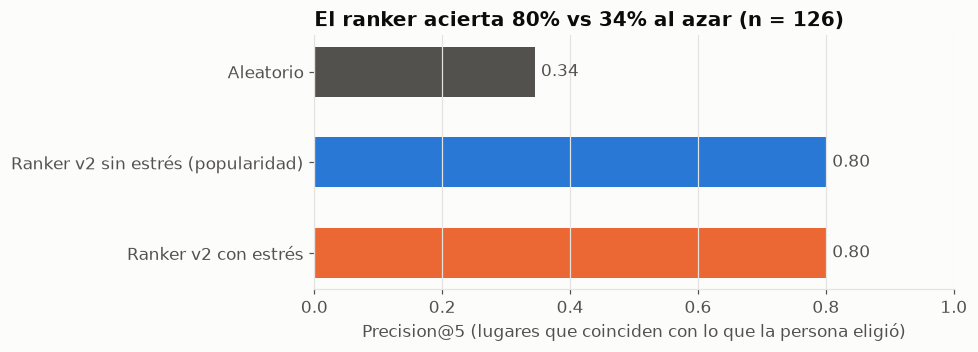

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 3))
vals = metricas['precision@5'].values
ax.barh(metricas.index[::-1], vals[::-1], color=[SERIES[1], SERIES[0], TEXTO_2], height=0.55)
for i, v in enumerate(vals[::-1]):
    ax.text(v + 0.01, i, f'{v:.2f}', va='center', color=TEXTO_2)
ax.set_xlim(0, 1); ax.set_xlabel('Precision@5 (lugares que coinciden con lo que la persona eligió)'); ax.grid(axis='y', visible=False)
ax.set_title(f"El ranker acierta {vals[2]:.0%} vs {vals[0]:.0%} al azar (n = {resumen['personas']})")
guardar(fig, '05_evaluacion_offline');

## Lectura
* El ranker v2 recomienda lugares que coinciden con lo que la gente dijo que le ayudaría a descansar mucho más que el azar.
* Añadir el estrés **no cambia de forma medible** la precisión a nivel de lugar: el efecto encontrado (relajación, OR 1.74) mueve los pesos, pero la naturaleza sigue siendo lo más elegido por casi todos. La personalización fuerte viene de las modalidades que la persona elige en la app.
* El ranker muestra pocos lugares distintos cuando no hay preferencias ni filtro de municipio: en la app, la región y las modalidades elegidas abren el resto del catálogo. Medir la exposición real de MiPyMEs requiere los registros de uso (impresiones ya se guardan por sesión).